In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
Tesla T4


In [3]:
!pip install -q datasets scikit-learn matplotlib gradio

In [4]:
from datasets import load_dataset

dataset = load_dataset("AutumnQiu/fer2013")
print(dataset)

README.md:   0%|          | 0.00/712 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  109MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/valid-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 13.6MB            

data/valid-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/28709 [00:00<?, ? examples/s]

Generating valid split:   0%|          | 0/3589 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3589 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'image'],
        num_rows: 28709
    })
    valid: Dataset({
        features: ['label', 'image'],
        num_rows: 3589
    })
    test: Dataset({
        features: ['label', 'image'],
        num_rows: 3589
    })
})


In [5]:
print(dataset["train"][0])

{'label': 0, 'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=48x48 at 0x7C4A7713CAD0>}


In [6]:
from datasets import load_dataset

dataset = load_dataset("AutumnQiu/fer2013")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['label', 'image'],
        num_rows: 28709
    })
    valid: Dataset({
        features: ['label', 'image'],
        num_rows: 3589
    })
    test: Dataset({
        features: ['label', 'image'],
        num_rows: 3589
    })
})


In [7]:
print(dataset["train"][0])

{'label': 0, 'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=48x48 at 0x7C4A772CEE90>}


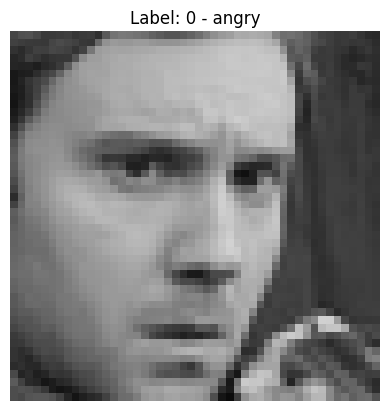

In [8]:
import matplotlib.pyplot as plt

emotion_names = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]

sample = dataset["train"][0]

image = sample["image"]
label = sample["label"]

plt.imshow(image)
plt.axis("off")
plt.title(f"Label: {label} - {emotion_names[label]}")
plt.show()

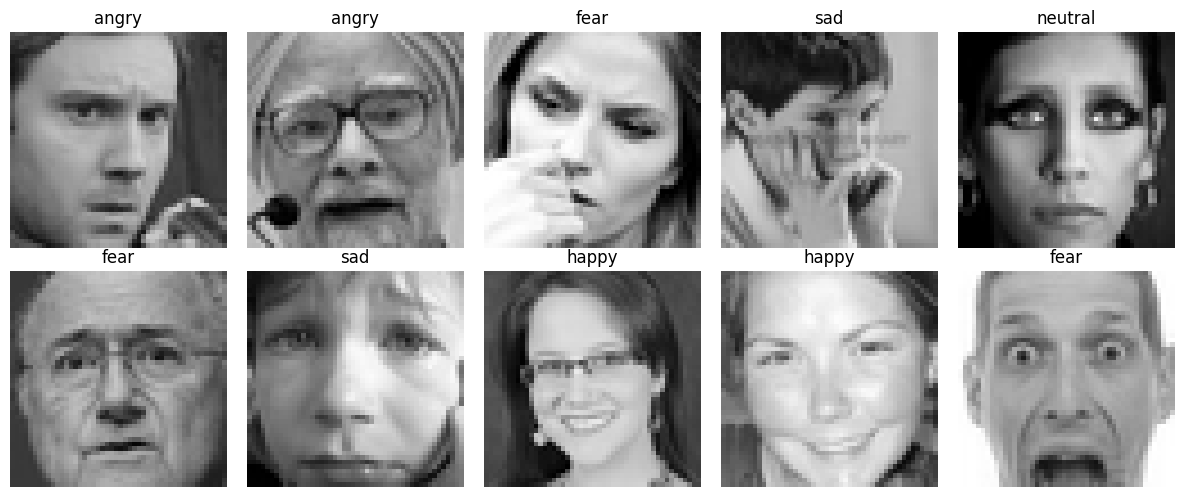

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    sample = dataset["train"][i]
    ax.imshow(sample["image"])
    ax.set_title(emotion_names[sample["label"]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]

Linear(in_features=512, out_features=1000, bias=True)


In [11]:
num_classes = 7

model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=7, bias=True)


In [12]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [13]:
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("总参数量:", total_params)
print("可训练参数量:", trainable_params)

总参数量: 11180103
可训练参数量: 3591


In [14]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [15]:
def train_transform_batch(batch):
    batch["pixel_values"] = [
        train_transform(img.convert("RGB"))
        for img in batch["image"]
    ]
    return batch

def eval_transform_batch(batch):
    batch["pixel_values"] = [
        eval_transform(img.convert("RGB"))
        for img in batch["image"]
    ]
    return batch

train_dataset = dataset["train"].with_transform(train_transform_batch)
valid_dataset = dataset["valid"].with_transform(eval_transform_batch)
test_dataset = dataset["test"].with_transform(eval_transform_batch)

In [16]:
from torch.utils.data import DataLoader

def collate_fn(batch):
    images = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch])
    return images, labels

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_fn
)

In [17]:
images, labels = next(iter(train_loader))

print("图片批次尺寸:", images.shape)
print("标签批次尺寸:", labels.shape)
print("前10个标签:", labels[:10])

图片批次尺寸: torch.Size([64, 3, 224, 224])
标签批次尺寸: torch.Size([64])
前10个标签: tensor([3, 4, 4, 6, 0, 2, 5, 3, 0, 2])


In [18]:
criterion = nn.CrossEntropyLoss()

In [19]:
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [20]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [21]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [22]:
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total

    return avg_loss, accuracy

In [23]:
print(evaluate)

<function evaluate at 0x7c4a4c289120>


In [24]:
num_epochs = 3

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        valid_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/3 | Train Loss: 1.6104 | Train Acc: 0.3670 | Val Loss: 1.5047 | Val Acc: 0.4296
Epoch 2/3 | Train Loss: 1.4863 | Train Acc: 0.4351 | Val Loss: 1.4808 | Val Acc: 0.4308
Epoch 3/3 | Train Loss: 1.4667 | Train Acc: 0.4408 | Val Loss: 1.4727 | Val Acc: 0.4408


In [25]:
torch.save(model.state_dict(), "moodmate_stage1.pth")
print("模型已保存")

模型已保存


In [26]:
for param in model.layer4.parameters():
    param.requires_grad = True

In [27]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

In [28]:
num_epochs = 3

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        valid_loader,
        criterion,
        device
    )

    print(
        f"Fine-tune Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Fine-tune Epoch 1/3 | Train Loss: 1.1758 | Train Acc: 0.5570 | Val Loss: 1.1204 | Val Acc: 0.5784
Fine-tune Epoch 2/3 | Train Loss: 0.8825 | Train Acc: 0.6779 | Val Loss: 1.0980 | Val Acc: 0.6088
Fine-tune Epoch 3/3 | Train Loss: 0.6615 | Train Acc: 0.7698 | Val Loss: 1.1332 | Val Acc: 0.6155


In [29]:
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Acc: {test_acc:.4f}")

Test Loss: 1.0405
Test Acc: 0.6369


In [30]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print(classification_report(
    all_labels,
    all_preds,
    target_names=emotion_names
))

              precision    recall  f1-score   support

       angry       0.59      0.54      0.56       491
     disgust       0.76      0.45      0.57        55
        fear       0.51      0.37      0.43       528
       happy       0.82      0.87      0.85       879
         sad       0.47      0.58      0.52       594
    surprise       0.68      0.85      0.75       416
     neutral       0.63      0.55      0.59       626

    accuracy                           0.64      3589
   macro avg       0.64      0.60      0.61      3589
weighted avg       0.63      0.64      0.63      3589



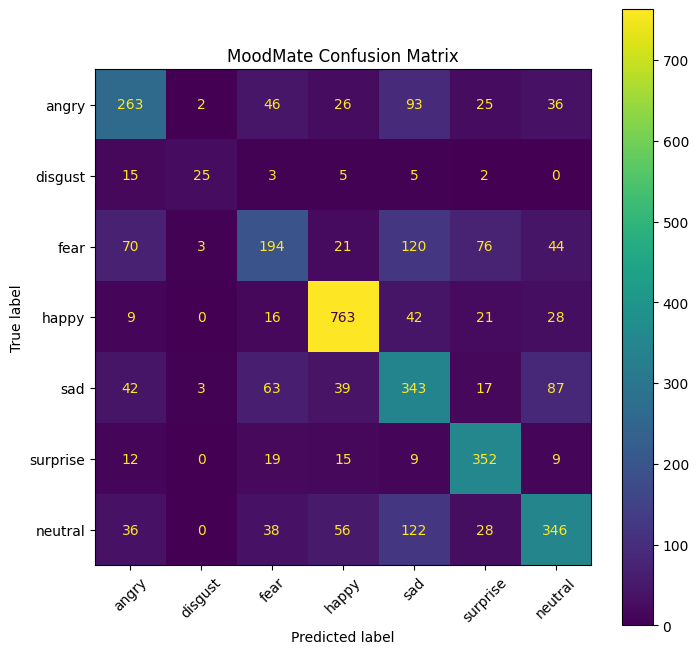

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=emotion_names
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("MoodMate Confusion Matrix")
plt.show()

In [32]:
torch.save(model.state_dict(), "moodmate_finetuned.pth")
print("最终微调模型已保存")

最终微调模型已保存


In [33]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [34]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [35]:
torch.save(
    model.state_dict(),
    "/content/drive/MyDrive/moodmate_finetuned.pth"
)

print("模型已保存到 Google Drive")

模型已保存到 Google Drive


In [36]:
import os

print(
    os.path.exists(
        "/content/drive/MyDrive/moodmate_finetuned.pth"
    )
)

True


In [37]:
import torch.nn.functional as F

def predict_emotion(image):
    # 确保是 RGB 图片
    image = image.convert("RGB")

    # 使用前面定义过的 eval_transform
    image_tensor = eval_transform(image)

    # 原来是 [3, 224, 224]
    # 模型需要 batch，所以增加一维
    image_tensor = image_tensor.unsqueeze(0)

    # 搬到 GPU
    image_tensor = image_tensor.to(device)

    # 告诉模型：现在是考试，不是训练
    model.eval()

    # 不需要计算梯度
    with torch.no_grad():

        # 模型给7种情绪打分
        outputs = model(image_tensor)

        # 转成概率
        probabilities = F.softmax(outputs, dim=1)

        # 找概率最大的情绪
        confidence, predicted = torch.max(
            probabilities,
            dim=1
        )

    emotion = emotion_names[predicted.item()]
    confidence = confidence.item()

    return emotion, confidence

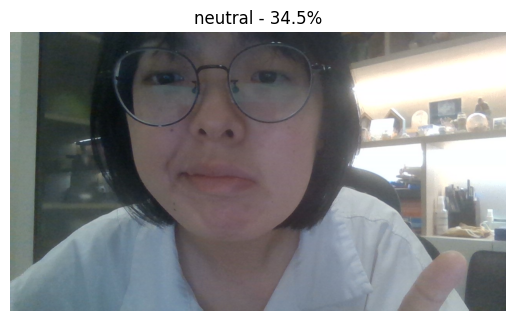

预测表情： neutral
置信度： 34.5%


In [38]:
from PIL import Image
import matplotlib.pyplot as plt

test_image = Image.open("/content/myface.jpg")

emotion, confidence = predict_emotion(test_image)

plt.imshow(test_image)
plt.axis("off")
plt.title(f"{emotion} - {confidence:.1%}")
plt.show()

print("预测表情：", emotion)
print("置信度：", f"{confidence:.1%}")

In [39]:
import cv2

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.14.0


In [40]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("人脸检测器加载成功")

人脸检测器加载成功


In [41]:
import matplotlib.pyplot as plt

image_cv = cv2.imread("/content/myface.jpg")

gray = cv2.cvtColor(image_cv, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(60, 60)
)

print("检测到的人脸数量：", len(faces))

检测到的人脸数量： 0


In [42]:
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 15.7 MB/s eta 0:00:00


In [43]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

mp_face_detection = mp.solutions.face_detection

image_cv = cv2.imread("/content/myface.jpg")
image_rgb = cv2.cvtColor(image_cv, cv2.COLOR_BGR2RGB)

with mp_face_detection.FaceDetection(
    model_selection=0,
    min_detection_confidence=0.5
) as face_detection:

    results = face_detection.process(image_rgb)

print("是否检测到人脸：", results.detections is not None)

AttributeError: module 'mediapipe' has no attribute 'solutions'

In [44]:
!wget -O face_detection_yunet_2023mar.onnx \
https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx

--2026-10-05 12:15:18--  https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx [following]
--2026-10-05 12:15:18--  https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx
Resolving media.githubusercontent.com (media.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to media.githubusercontent.com (media.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 232589 (227K) [application/octet-stream]
Saving to: ‘face_detection_yunet_2023mar.onnx’

face_detection_

In [45]:
import cv2

detector = cv2.FaceDetectorYN.create(
    "/content/face_detection_yunet_2023mar.onnx",
    "",
    (320, 320),
    score_threshold=0.6,
    nms_threshold=0.3,
    top_k=5000
)

print("YuNet 人脸检测器加载成功")

YuNet 人脸检测器加载成功


In [46]:
image_cv = cv2.imread("/content/myface.jpg")

h, w = image_cv.shape[:2]

detector.setInputSize((w, h))

_, faces = detector.detect(image_cv)

if faces is None:
    print("没有检测到人脸")
else:
    print("检测到的人脸数量：", len(faces))

检测到的人脸数量： 1


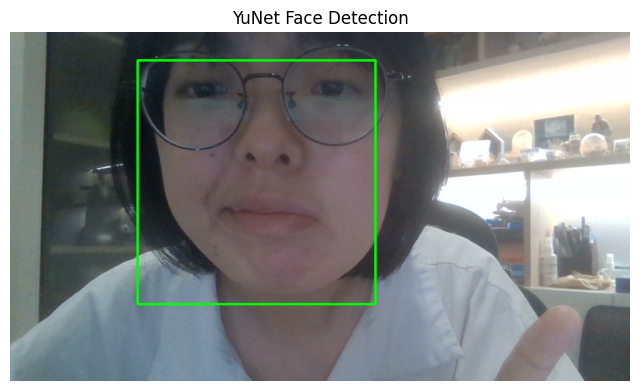

In [47]:
import matplotlib.pyplot as plt

display_image = image_cv.copy()

if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)

        cv2.rectangle(
            display_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

display_image_rgb = cv2.cvtColor(
    display_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 6))
plt.imshow(display_image_rgb)
plt.axis("off")
plt.title("YuNet Face Detection")
plt.show()

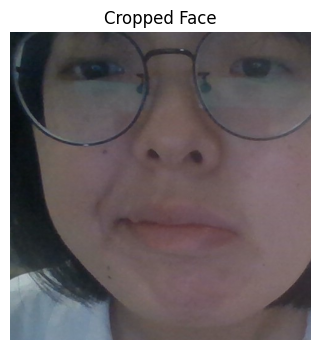

In [48]:
from PIL import Image

if faces is not None:
    face = faces[0]

    x, y, w, h = face[:4].astype(int)

    # 防止坐标跑出图片边界
    x = max(0, x)
    y = max(0, y)

    face_crop = image_cv[
        y:y+h,
        x:x+w
    ]

    face_crop_rgb = cv2.cvtColor(
        face_crop,
        cv2.COLOR_BGR2RGB
    )

    face_pil = Image.fromarray(face_crop_rgb)

    plt.figure(figsize=(4, 4))
    plt.imshow(face_pil)
    plt.axis("off")
    plt.title("Cropped Face")
    plt.show()

In [49]:
if faces is not None:
    emotion, confidence = predict_emotion(face_pil)

    print("预测表情：", emotion)
    print("置信度：", f"{confidence:.1%}")

预测表情： happy
置信度： 70.6%


In [11]:
import numpy as np
from PIL import Image, ImageDraw
import cv2


from PIL import Image, ImageDraw
import numpy as np

# 记录当前已经显示在页面上的文案
current_messages = []

# 记录当前页面正在使用的稳定情绪
display_emotion = None


def process_camera_frame(frame):
    global current_messages
    global display_emotion

    if frame is None:
        return None, "WAITING", "等待摄像头画面..."

    # 1. Gradio传进来的是PIL图片
    frame = frame.convert("RGB")

    # 2. PIL → numpy
    image_rgb = np.array(frame)

    # 3. RGB → BGR，给OpenCV/YuNet用
    image_bgr = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2BGR
    )

    # 4. 获取画面尺寸
    h, w = image_bgr.shape[:2]

    # 5. 告诉YuNet当前画面有多大
    detector.setInputSize((w, h))

    # 6. YuNet检测人脸
    _, faces = detector.detect(image_bgr)

    # 没找到脸
    if faces is None or len(faces) == 0:

        # 如果之前已经识别出稳定情绪，就保留原来的结果
        if display_emotion is not None:

            message_text = "\n".join(
                ["• " + msg for msg in current_messages]
            )

            return (
                frame,
                display_emotion.upper(),
                message_text
            )

        return (
            frame,
            "NO FACE",
            "镜子里没人，你让我识别空气啊？"
        )

    # 7. 多张脸时，取最大的一张
    face = max(
        faces,
        key=lambda f: f[2] * f[3]
    )

    x, y, fw, fh = face[:4].astype(int)

    # 防止坐标越界
    x = max(0, x)
    y = max(0, y)

    x2 = min(w, x + fw)
    y2 = min(h, y + fh)

    # 8. 裁剪人脸
    face_crop = image_rgb[
        y:y2,
        x:x2
    ]

    if face_crop.size == 0:
        return (
            frame,
            "ERROR",
            "脸是看见了，但没裁下来。"
        )

    # 9. numpy → PIL
    face_pil = Image.fromarray(face_crop)

    # 10. ResNet18进行表情识别
    emotion, confidence = predict_emotion(face_pil)

    # 11. 情绪稳定器
    current_stable_emotion, emotion_changed = update_stable_emotion(
        emotion,
        confidence
    )

    # 12. 在摄像头画面上画人脸框
    output_image = frame.copy()

    draw = ImageDraw.Draw(output_image)

    draw.rectangle(
        [x, y, x2, y2],
        outline="lime",
        width=4
    )

    # 13. 还没积累够稳定结果
    if current_stable_emotion is None:
        return (
            output_image,
            "ANALYZING...",
            f"正在观察你...\n瞬时识别：{emotion.upper()}  {confidence:.0%}"
        )

    # 14. 只有稳定情绪真正变化时，才重新抽话术
    if emotion_changed or display_emotion is None:

        display_emotion = current_stable_emotion

        current_messages = get_random_messages(
            display_emotion
        )

    # 15. 把2～3句话拼起来
    message_text = "\n\n".join(
        ["• " + msg for msg in current_messages]
    )

    # 顺便显示模型当前置信度
    message_text += (
        f"\n\n"
        f"瞬时识别：{emotion.upper()} · {confidence:.0%}"
    )

    # 16. 返回三个东西：
    # 摄像头画面
    # 大写情绪
    # 阴阳文案
    return (
        output_image,
        display_emotion.upper(),
        message_text
    )

In [17]:
import gradio as gr

with gr.Blocks() as demo:

    gr.Markdown(
        "# MoodMate\n"
        "实时面部表情感知 Demo"
    )

    with gr.Row():

        webcam = gr.Image(
            sources=["webcam"],
            type="pil",
            label="摄像头",
            streaming=True
        )

        output_image = gr.Image(
            label="识别结果"
        )

    emotion_output = gr.Textbox(
        label="当前表情识别"
    )

    webcam.stream(
    fn=process_camera_frame,
    inputs=webcam,
    outputs=[
        emotion_panel
    ],
    stream_every=5
)

demo.launch(
    share=True,
    debug=False
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cbe22bd746ad51b0db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [53]:
from collections import deque, Counter

# 保存最近 8 次识别结果
emotion_history = deque(maxlen=8)

# 当前已经确认的稳定情绪
stable_emotion = None

# 最低置信度
CONFIDENCE_THRESHOLD = 0.55

# 最近 8 次里，至少 5 次相同才确认
MIN_VOTES = 5


def update_stable_emotion(emotion, confidence):
    global stable_emotion

    # 每次识别结果都记录下来
    emotion_history.append((emotion, confidence))

    # 只把置信度 >= 55% 的结果认为“可信”
    valid_results = [
        (e, c)
        for e, c in emotion_history
        if c >= CONFIDENCE_THRESHOLD
    ]

    # 可信结果连 5 个都没有，就先不下结论
    if len(valid_results) < MIN_VOTES:
        return stable_emotion, False

    # 看最近这些可信结果里，哪个情绪出现最多
    emotions = [e for e, c in valid_results]

    counter = Counter(emotions)

    top_emotion, top_count = counter.most_common(1)[0]

    # 出现次数还不够
    if top_count < MIN_VOTES:
        return stable_emotion, False

    # 再计算这个情绪自己的平均置信度
    confidences = [
        c
        for e, c in valid_results
        if e == top_emotion
    ]

    avg_confidence = sum(confidences) / len(confidences)

    if avg_confidence < CONFIDENCE_THRESHOLD:
        return stable_emotion, False

    # 判断这次是不是发生了真正的情绪变化
    changed = top_emotion != stable_emotion

    stable_emotion = top_emotion

    return stable_emotion, changed


In [55]:
import os

print(os.path.exists(
    "/content/drive/MyDrive/moodmate_finetuned.pth"
))

True


In [56]:
import shutil

shutil.copy(
    "/content/face_detection_yunet_2023mar.onnx",
    "/content/drive/MyDrive/face_detection_yunet_2023mar.onnx"
)

print("YuNet 已备份到 Drive")

YuNet 已备份到 Drive


In [1]:
print("model:", "model" in globals())
print("detector:", "detector" in globals())
print("predict_emotion:", "predict_emotion" in globals())
print("update_stable_emotion:", "update_stable_emotion" in globals())

model: False
detector: False
predict_emotion: False
update_stable_emotion: False


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch
import torch.nn as nn
from torchvision import models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

emotion_names = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 7)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/moodmate_finetuned.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("ResNet18 情绪模型加载成功")

ResNet18 情绪模型加载成功


In [4]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
import torch.nn.functional as F

def predict_emotion(image):
    image = image.convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)
        confidence, predicted = torch.max(probabilities, dim=1)

    emotion = emotion_names[predicted.item()]
    confidence = confidence.item()

    return emotion, confidence

In [6]:
import cv2

detector = cv2.FaceDetectorYN.create(
    "/content/drive/MyDrive/face_detection_yunet_2023mar.onnx",
    "",
    (320, 320),
    score_threshold=0.6,
    nms_threshold=0.3,
    top_k=5000
)

print("YuNet 人脸检测器加载成功")

YuNet 人脸检测器加载成功


In [7]:
from collections import deque, Counter

emotion_history = deque(maxlen=8)
stable_emotion = None

CONFIDENCE_THRESHOLD = 0.55
MIN_VOTES = 5

def update_stable_emotion(emotion, confidence):
    global stable_emotion

    emotion_history.append((emotion, confidence))

    valid_results = [
        (e, c)
        for e, c in emotion_history
        if c >= CONFIDENCE_THRESHOLD
    ]

    if len(valid_results) < MIN_VOTES:
        return stable_emotion, False

    emotions = [e for e, c in valid_results]
    counter = Counter(emotions)

    top_emotion, top_count = counter.most_common(1)[0]

    if top_count < MIN_VOTES:
        return stable_emotion, False

    confidences = [
        c
        for e, c in valid_results
        if e == top_emotion
    ]

    avg_confidence = sum(confidences) / len(confidences)

    if avg_confidence < CONFIDENCE_THRESHOLD:
        return stable_emotion, False

    changed = top_emotion != stable_emotion
    stable_emotion = top_emotion

    return stable_emotion, changed

In [8]:
print("model:", "model" in globals())
print("detector:", "detector" in globals())
print("predict_emotion:", "predict_emotion" in globals())
print("update_stable_emotion:", "update_stable_emotion" in globals())

model: True
detector: True
predict_emotion: True
update_stable_emotion: True


In [9]:
import random

EMOTION_COLORS = {
    "angry": "#FF4D6D",
    "disgust": "#A8E063",
    "fear": "#6674FF",
    "happy": "#FFD60A",
    "sad": "#5E8BFF",
    "surprise": "#D05CFF",
    "neutral": "#43D9C0"
}


PHRASE_PARTS = {

    "angry": {
        "starts": [
            "这就破防？",
            "不是，真生气啦？",
            "谁又惹我们大明星了，",
            "这个脸色有点东西，",
            "谁把你 CPU 干烧了，",
            "今天火气有点旺啊，",
            "表情管理掉线了是吧，",
            "哟，情绪开始上强度了，",
            "谁这么精准踩你雷区了，",
            "你这个状态进入战斗模式了，"
        ],
        "ends": [
            "小妹妹你蛮牛逼克拉斯啊。",
            "再气两秒就可以直接上强度了。",
            "建议先别回消息，容易留下证据。",
            "别急，互联网还没值得你这么认真。",
            "先收收火，不然镜子都要热了。"
        ]
    },

    "happy": {
        "starts": [
            "666，",
            "哟，嘴角压不住了，",
            "这个表情有情况，",
            "看来今天有点大结果，",
            "怎么偷偷开心上了，",
            "笑这么明显，",
            "今天状态直接起飞，",
            "一看就没憋什么好事，",
            "好好好，背着我发财是吧，",
            "这个笑容多少有点故事，"
        ],
        "ends": [
            "拿到大结果了不告诉我？",
            "说吧，谁给你发好消息了。",
            "别装，开心都写脸上了。",
            "嘴角都快飞到天花板了。",
            "有喜事记得分我一半。"
        ]
    },

    "sad": {
        "starts": [
            "哟，又网易云上了，",
            "怎么突然进入深夜电台模式了，",
            "这个表情有点苦情剧，",
            "不是，谁把你情绪 KPI 干没了，",
            "今天状态有点低电量啊，",
            "怎么回事，灵魂掉线了？",
            "这个脸看起来被生活教育了，",
            "今天怎么一副世界欠你五百万的样子，",
            "看样子今天剧情不太顺利，",
            "好家伙，直接 emo 启动，"
        ],
        "ends": [
            "别低头，皇冠会掉，虽然你也没皇冠。",
            "先别急，人生还没加载完。",
            "允许你摆两分钟，不能再多了。",
            "问题不大，互联网明天照样发疯。",
            "今天先这样，明天再重新做人。"
        ]
    },

    "neutral": {
        "starts": [
            "好一个波澜不惊，",
            "CPU 在线，情绪模块未启动，",
            "这个表情主打一个无事发生，",
            "今天是电子木鱼模式是吧，",
            "你现在像个默认头像，",
            "表情加载进度百分之零，",
            "不悲不喜，有点大师风范，",
            "这个状态突出一个随便吧，",
            "灵魂今天请假了？",
            "看起来一切都很一般，"
        ],
        "ends": [
            "主打一个情绪稳定。",
            "继续保持，谁都别来沾边。",
            "可以，今天属于低功耗运行。",
            "没事，系统至少还没崩。",
            "这状态很适合装高手。"
        ]
    },

    "surprise": {
        "starts": [
            "哟，这是看到什么大瓜了，",
            "眼睛睁这么大干嘛，",
            "不是，发生什么了，",
            "这个表情一下有节目效果了，",
            "怎么突然震惊部入驻了，",
            "等一下，你看到了什么，",
            "好家伙，CPU突然拉满，",
            "这个反应有点夸张啊，",
            "什么消息能把你吓成这样，",
            "你这个表情已经自带感叹号了，"
        ],
        "ends": [
            "Excel 又炸了？",
            "是好消息还是互联网又发疯了？",
            "别急，让我也吃口瓜。",
            "世界一直这么癫，习惯就好。",
            "建议先截图留证。"
        ]
    },

    "fear": {
        "starts": [
            "怎么，老板突然 @ 你了？",
            "这个表情像看到截止日期了，",
            "你怎么看起来有点慌，",
            "不会吧，不会真出事了吧，",
            "这个眼神有种论文要送审的美，",
            "不是，谁吓你了，",
            "你这个状态像突然想起还有作业，",
            "怎么突然进入紧急模式，",
            "好像大脑正在疯狂弹窗，",
            "这个表情有点危险预警，"
        ],
        "ends": [
            "慌什么，天还没塌。",
            "最多就是 PPT 没保存。",
            "先别自己把自己吓死。",
            "问题来了再解决，别提前付利息。",
            "深呼吸，CPU别烧了。"
        ]
    },

    "disgust": {
        "starts": [
            "这个嫌弃有点明显了，",
            "好家伙，白眼差点翻到后脑勺，",
            "什么东西能让你露出这个表情，",
            "一看就是不太入您的法眼，",
            "这个脸已经替你打了一星，",
            "好一个肉眼可见的嫌弃，",
            "你这个表情多少有点攻击性，",
            "懂了，不想看第二眼，",
            "这是谁又踩你审美雷区了，",
            "不是，你嫌弃得也太明显了，"
        ],
        "ends": [
            "不喜欢就别勉强，互联网够累了。",
            "建议直接划走。",
            "这个东西可能确实配不上你。",
            "懂了，差评已经写脸上了。",
            "眼不见心不烦，下一位。"
        ]
    }
}


def get_random_messages(emotion):
    if emotion not in PHRASE_PARTS:
        emotion = "neutral"

    starts = PHRASE_PARTS[emotion]["starts"]
    ends = PHRASE_PARTS[emotion]["ends"]

    all_messages = [
        start + end
        for start in starts
        for end in ends
    ]

    number = random.choice([2, 3])

    return random.sample(all_messages, k=number)

In [10]:
emotion = "happy"

messages = get_random_messages(emotion)

print("实时情绪：", emotion.upper())
print("背景颜色：", EMOTION_COLORS[emotion])

for msg in messages:
    print("•", msg)

实时情绪： HAPPY
背景颜色： #FFD60A
• 一看就没憋什么好事，说吧，谁给你发好消息了。
• 一看就没憋什么好事，别装，开心都写脸上了。
• 笑这么明显，拿到大结果了不告诉我？


In [12]:
def build_emotion_panel(emotion, messages, confidence=None):

    # 还没有识别出稳定情绪
    if emotion is None:
        emotion = "neutral"

    color = EMOTION_COLORS.get(
        emotion,
        EMOTION_COLORS["neutral"]
    )

    # 英文情绪 → 中文小标题
    emotion_cn = {
        "angry": "生气",
        "disgust": "嫌弃",
        "fear": "紧张",
        "happy": "开心",
        "sad": "低落",
        "surprise": "震惊",
        "neutral": "平静"
    }.get(emotion, "观察中")

    # 把2～3句话变成HTML
    message_html = ""

    for msg in messages:
        message_html += f"""
        <div class="mood-line">
            {msg}
        </div>
        """

    # 如果有置信度，就显示
    confidence_html = ""

    if confidence is not None:
        confidence_html = f"""
        <div class="confidence">
            MODEL CONFIDENCE · {confidence:.0%}
        </div>
        """

    html = f"""
    <div
        class="emotion-panel"
        style="background:{color};"
    >

        <div class="emotion-small">
            MOODMATE SEES
        </div>

        <div class="emotion-title">
            {emotion.upper()}
        </div>

        <div class="emotion-cn">
            {emotion_cn}
        </div>

        {confidence_html}

        <div class="message-area">
            {message_html}
        </div>

        <div class="bottom-caption">
            MOODMATE · DON'T TAKE IT TOO SERIOUSLY
        </div>

    </div>
    """

    return html

In [13]:
def build_emotion_panel(emotion, messages, confidence=None):

    if emotion is None:
        emotion = "neutral"

    color = EMOTION_COLORS.get(
        emotion,
        EMOTION_COLORS["neutral"]
    )

    emotion_cn = {
        "angry": "生气",
        "disgust": "嫌弃",
        "fear": "紧张",
        "happy": "开心",
        "sad": "低落",
        "surprise": "震惊",
        "neutral": "平静"
    }.get(emotion, "观察中")

    message_html = ""

    for msg in messages:
        message_html += f"""
        <div class="mood-line">
            {msg}
        </div>
        """

    confidence_html = ""

    if confidence is not None:
        confidence_html = f"""
        <div class="confidence">
            MODEL CONFIDENCE · {confidence:.0%}
        </div>
        """

    html = f"""
    <div
        class="emotion-panel"
        style="background:{color};"
    >

        <div class="emotion-small">
            MOODMATE SEES
        </div>

        <div class="emotion-title">
            {emotion.upper()}
        </div>

        <div class="emotion-cn">
            {emotion_cn}
        </div>

        {confidence_html}

        <div class="message-area">
            {message_html}
        </div>

        <div class="bottom-caption">
            MOODMATE · DON'T TAKE IT TOO SERIOUSLY
        </div>

    </div>
    """

    return html

In [14]:
from PIL import Image, ImageDraw
import numpy as np

# 当前页面上正在显示的文案
current_messages = []

# 当前稳定情绪
display_emotion = None

# 当前置信度
display_confidence = None


def process_camera_frame(frame):
    global current_messages
    global display_emotion
    global display_confidence

    # 还没有摄像头画面
    if frame is None:
        waiting_html = """
        <div class="emotion-panel waiting-panel">
            <div class="emotion-small">
                MOODMATE SEES
            </div>

            <div class="emotion-title">
                WAITING
            </div>

            <div class="message-area">
                <div class="mood-line">
                    镜子开了，人呢？
                </div>
            </div>
        </div>
        """

        return None, waiting_html

    # Gradio传进来的是PIL图片
    frame = frame.convert("RGB")

    # PIL → numpy
    image_rgb = np.array(frame)

    # RGB → BGR，给OpenCV/YuNet用
    image_bgr = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2BGR
    )

    # 当前画面大小
    h, w = image_bgr.shape[:2]

    # 告诉YuNet输入尺寸
    detector.setInputSize((w, h))

    # 找人脸
    _, faces = detector.detect(image_bgr)

    # 没检测到脸
    if faces is None or len(faces) == 0:

        # 如果之前已经有稳定结果，就先保留
        if display_emotion is not None:
            panel = build_emotion_panel(
                display_emotion,
                current_messages,
                display_confidence
            )

            return frame, panel

        no_face_html = """
        <div class="emotion-panel no-face-panel">

            <div class="emotion-small">
                MOODMATE SEES
            </div>

            <div class="emotion-title">
                NO FACE
            </div>

            <div class="message-area">
                <div class="mood-line">
                    镜子里没人。
                </div>

                <div class="mood-line">
                    你让我识别空气是吧。
                </div>
            </div>

        </div>
        """

        return frame, no_face_html

    # 如果有多张脸，就取最大的一张
    face = max(
        faces,
        key=lambda f: f[2] * f[3]
    )

    x, y, fw, fh = face[:4].astype(int)

    # 防止坐标越界
    x = max(0, x)
    y = max(0, y)

    x2 = min(w, x + fw)
    y2 = min(h, y + fh)

    # 裁剪人脸
    face_crop = image_rgb[
        y:y2,
        x:x2
    ]

    if face_crop.size == 0:
        return frame, """
        <div class="emotion-panel no-face-panel">
            <div class="emotion-title">
                ERROR
            </div>
        </div>
        """

    # numpy → PIL
    face_pil = Image.fromarray(face_crop)

    # ResNet18表情识别
    emotion, confidence = predict_emotion(
        face_pil
    )

    # 情绪稳定器
    current_stable_emotion, emotion_changed = (
        update_stable_emotion(
            emotion,
            confidence
        )
    )

    # 复制摄像头画面
    output_image = frame.copy()

    # 在脸上画框
    draw = ImageDraw.Draw(output_image)

    draw.rectangle(
        [x, y, x2, y2],
        outline="white",
        width=4
    )

    # 还没得到稳定情绪
    if current_stable_emotion is None:

        analyzing_html = f"""
        <div class="emotion-panel analyzing-panel">

            <div class="emotion-small">
                MOODMATE SEES
            </div>

            <div class="emotion-title">
                ANALYZING
            </div>

            <div class="confidence">
                CURRENT GUESS · {emotion.upper()} · {confidence:.0%}
            </div>

            <div class="message-area">

                <div class="mood-line">
                    别动，让我看看你今天又是什么状态。
                </div>

            </div>

        </div>
        """

        return output_image, analyzing_html

    # 只有稳定情绪真的变化时才换文案
    if emotion_changed or display_emotion is None:

        display_emotion = current_stable_emotion

        display_confidence = confidence

        current_messages = get_random_messages(
            display_emotion
        )

    # 生成右边情绪页面
    panel_html = build_emotion_panel(
        display_emotion,
        current_messages,
        display_confidence
    )

    return output_image, panel_html

In [24]:
import gradio as gr

custom_css = """
/* 整体页面 */
.gradio-container {
    max-width: 1500px !important;
    margin: auto !important;
    transition: background 0.3s ease !important;
    box-shadow: none !important;
}

/* 顶部标题 */
#main-title {
    text-align: center;
    margin-top: 16px;
    margin-bottom: 18px;
}

#main-title h1 {
    font-size: 56px;
    font-weight: 900;
    margin: 0;
    color: #222;
    letter-spacing: -2px;
}

/* 左边镜子区 */
#mirror-camera {
    border-radius: 999px !important;
    padding: 18px !important;
    background: linear-gradient(
        135deg,
        #F6D56E 0%,
        #A36A00 18%,
        #F9E8AE 38%,
        #8F5B00 58%,
        #E4BE4A 78%,
        #6A4300 100%
    ) !important;
    box-shadow: 0 16px 40px rgba(0,0,0,0.18) !important;
    overflow: hidden !important;
}

/* 去掉默认外框/标签影响 */
#mirror-camera > div,
#mirror-camera .wrap,
#mirror-camera .image-container,
#mirror-camera .preview {
    border-radius: 999px !important;
    overflow: hidden !important;
    background: transparent !important;
    border: none !important;
}

/* 真正的摄像头画面 */
#mirror-camera video,
#mirror-camera img {
    width: 100% !important;
    aspect-ratio: 16 / 9 !important;
    object-fit: cover !important;
    border-radius: 999px !important;
    display: block !important;
    background: white !important;
    border: 8px solid #FFF4CF !important;
}

/* 按钮 */
.action-row {
    margin-top: 16px;
    justify-content: center !important;
}

#snap-btn button,
#clear-btn button {
    border-radius: 18px !important;
    font-size: 18px !important;
    font-weight: 800 !important;
    padding: 14px 24px !important;
    border: none !important;
}

#snap-btn button {
    background: #111 !important;
    color: white !important;
}

#clear-btn button {
    background: white !important;
    color: #222 !important;
}

/* 右侧情绪区 */
.emotion-panel {
    min-height: 420px;
    padding: 30px 20px;
    box-sizing: border-box;
    color: #1E1E1E;
}

.emotion-small {
    font-size: 16px;
    font-weight: 800;
    letter-spacing: 6px;
    opacity: 0.7;
    margin-bottom: 12px;
}

.emotion-title {
    font-size: 92px;
    font-weight: 900;
    line-height: 0.95;
    margin-bottom: 12px;
}

.emotion-cn {
    font-size: 34px;
    font-weight: 800;
    margin-bottom: 20px;
}

.confidence-line {
    font-size: 18px;
    font-weight: 700;
    letter-spacing: 2px;
    opacity: 0.7;
    margin-bottom: 36px;
}

.message-box {
    font-size: 36px;
    line-height: 1.45;
    font-weight: 900;
    max-width: 95%;
}

/* 隐藏多余 label 小字 */
.hide-label label,
.hide-label .label-wrap,
.hide-label .block-title {
    display: none !important;
}

/* 隐藏底部 footer */
footer {
    display: none !important;
}
"""


with gr.Blocks() as demo:

    # 这个用来偷偷改整个页面颜色
    page_style_output = gr.HTML(
        build_page_style("#E8DDC8"),
        elem_id="page-style-output"
    )

    gr.HTML("""
    <div id="main-title">
        <h1>MOODMATE</h1>
    </div>
    """)

    with gr.Row():

        # 左边摄像头
        with gr.Column(scale=6):
            webcam = gr.Image(
                sources=["webcam"],
                type="pil",
                label=None,
                show_label=False,
                container=False,
                elem_id="mirror-camera"
            )

            with gr.Row(elem_classes=["action-row"]):
                snap_btn = gr.Button(
                    "识别一下",
                    elem_id="snap-btn"
                )

                clear_btn = gr.Button(
                    "清空重来",
                    elem_id="clear-btn"
                )

        # 右边情绪显示
        with gr.Column(scale=6):
            emotion_panel = gr.HTML(
                build_waiting_panel()
            )

    # 点击“识别一下”
    snap_btn.click(
        fn=analyze_one_photo,
        inputs=webcam,
        outputs=[emotion_panel, page_style_output]
    )

    # 点击“清空重来”
    clear_btn.click(
        fn=lambda: (
            build_waiting_panel(),
            build_page_style("#E8DDC8")
        ),
        inputs=[],
        outputs=[emotion_panel, page_style_output]
    )

demo.launch(
    share=True,
    debug=False,
    css=custom_css
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bd1f454ae24c521159.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [26]:
import gradio as gr


# =========================
# CSS
# =========================

custom_css = """

.gradio-container {
    max-width: 1500px !important;
    margin: auto !important;
    min-height: 100vh !important;
    transition: background 0.35s ease !important;
}


/* ======================
   标题
====================== */

#main-title {
    text-align: center;
    padding-top: 30px;
    margin-bottom: 25px;
}

#main-title h1 {
    font-size: 58px;
    font-weight: 900;
    letter-spacing: -3px;
    color: #202020;
    margin: 0;
}


/* ======================
   左边魔镜
====================== */

#mirror-wrapper {

    position: relative;

    width: 100%;

    padding: 18px;

    border-radius: 180px;

    background:
        linear-gradient(
            135deg,
            #815000 0%,
            #D69A13 12%,
            #FFE38A 23%,
            #A56D00 37%,
            #F6CE55 52%,
            #7A4900 67%,
            #F6D669 82%,
            #8A5700 100%
        );

    box-shadow:
        0 18px 45px
        rgba(0,0,0,0.22);

    box-sizing: border-box;
}


/* 第二层镜框 */

#mirror-inner {

    border:

        7px solid
        #FFF1B8;

    border-radius: 165px;

    overflow: hidden;

    background: #111;

    position: relative;
}


/* 真正实时摄像头 */

#mood-video {

    display: block;

    width: 100%;

    aspect-ratio: 16 / 9;

    object-fit: cover;

    transform: scaleX(-1);

    background: #111;
}


/* 拍照瞬间的白色快门 */

#flash-layer {

    position: absolute;

    inset: 0;

    background: white;

    opacity: 0;

    pointer-events: none;

    z-index: 20;

    border-radius: 155px;
}


/* 冻结截图 */

#freeze-canvas {

    display: none;

    position: absolute;

    inset: 0;

    width: 100%;

    height: 100%;

    object-fit: cover;

    z-index: 10;
}


/* ======================
   按钮
====================== */

#capture-button button {

    width: 100%;

    margin-top: 18px;

    border-radius: 20px !important;

    padding: 15px !important;

    font-size: 19px !important;

    font-weight: 900 !important;

    background: #171717 !important;

    color: white !important;

    border: none !important;
}


/* ======================
   右边
====================== */

.emotion-panel {

    min-height: 430px;

    padding:
        40px
        20px;

    box-sizing: border-box;

    color: #202020;
}


.emotion-small {

    font-size: 15px;

    font-weight: 800;

    letter-spacing: 6px;

    opacity: 0.65;

    margin-bottom: 12px;
}


.emotion-title {

    font-size: 96px;

    line-height: 0.92;

    font-weight: 900;

    letter-spacing: -5px;

    margin-bottom: 18px;
}


.emotion-cn {

    font-size: 35px;

    font-weight: 900;

    margin-bottom: 18px;
}


.confidence-line {

    font-size: 17px;

    font-weight: 800;

    letter-spacing: 2px;

    opacity: 0.65;

    margin-bottom: 38px;
}


.message-box {

    font-size: 38px;

    font-weight: 900;

    line-height: 1.4;

    max-width: 95%;
}


/* 隐藏我们用来传截图的输入框 */

#snapshot-data {
    display: none !important;
}


footer {
    display: none !important;
}

"""


# =========================
# JavaScript
# =========================

custom_js = r"""
async () => {

    const sleep = (ms) =>
        new Promise(resolve => setTimeout(resolve, ms));

    // 等待Gradio把页面DOM渲染完成
    await sleep(500);

    const video =
        document.getElementById("mood-video");

    if (!video) {
        console.log("MoodMate video not found");
        return;
    }

    try {

        const stream =
            await navigator.mediaDevices.getUserMedia({
                video: {
                    width: { ideal: 1280 },
                    height: { ideal: 720 },
                    facingMode: "user"
                },
                audio: false
            });

        video.srcObject = stream;

        await video.play();

    } catch (err) {

        console.error(
            "Camera error:",
            err
        );
    }
}
"""


with gr.Blocks() as demo:

    # 用于动态改变整个页面背景
    page_style_output = gr.HTML(
        build_page_style("#E8DDC8")
    )

    gr.HTML(
        """
        <div id="main-title">
            <h1>MOODMATE</h1>
        </div>
        """
    )


    with gr.Row():

        # ========================
        # 左边
        # ========================

        with gr.Column(scale=6):

            gr.HTML(
                """
                <div id="mirror-wrapper">

                    <div id="mirror-inner">

                        <video
                            id="mood-video"
                            autoplay
                            playsinline
                            muted>
                        </video>

                        <canvas
                            id="freeze-canvas">
                        </canvas>

                        <div
                            id="flash-layer">
                        </div>

                    </div>

                </div>
                """
            )

            # 这个textbox用户看不到
            # JS截图后会把base64放进这里
            snapshot_data = gr.Textbox(
                value="",
                elem_id="snapshot-data",
                visible=True
            )

            capture_btn = gr.Button(
                "识别一下",
                elem_id="capture-button"
            )


        # ========================
        # 右边
        # ========================

        with gr.Column(scale=6):

            emotion_panel = gr.HTML(
                build_waiting_panel()
            )


    # =========================
    # 点击识别
    # =========================

    capture_btn.click(

        fn=analyze_snapshot,

        inputs=snapshot_data,

        outputs=[
            emotion_panel,
            page_style_output
        ],

        # 非常关键：
        # Python运行前，先在浏览器截取当前video
        js=r"""
        async (old_value) => {

            const video =
                document.getElementById("mood-video");

            const canvas =
                document.getElementById("freeze-canvas");

            const flash =
                document.getElementById("flash-layer");


            if (!video ||
                video.videoWidth === 0) {

                return "";
            }


            /* 创建临时画布 */

            const shot =
                document.createElement("canvas");

            shot.width =
                video.videoWidth;

            shot.height =
                video.videoHeight;

            const ctx =
                shot.getContext("2d");


            /*
            因为video为了像镜子一样左右翻转了，
            截图也做同样翻转。
            */

            ctx.translate(
                shot.width,
                0
            );

            ctx.scale(
                -1,
                1
            );

            ctx.drawImage(
                video,
                0,
                0,
                shot.width,
                shot.height
            );


            /* ==================
               0.5秒冻结效果
            ================== */

            canvas.width =
                shot.width;

            canvas.height =
                shot.height;

            const freezeCtx =
                canvas.getContext("2d");

            freezeCtx.drawImage(
                shot,
                0,
                0
            );

            canvas.style.display =
                "block";


            /* 白色快门闪一下 */

            flash.style.opacity = "0.75";

            setTimeout(
                () => {
                    flash.style.opacity = "0";
                },
                100
            );


            /* 0.5秒后恢复实时video */

            setTimeout(
                () => {
                    canvas.style.display = "none";
                },
                500
            );


            /* 转成base64传给Python */

            const data =
                shot.toDataURL(
                    "image/jpeg",
                    0.92
                );

            return data;
        }
        """
    )


demo.launch(
    share=True,
    debug=False,
    css=custom_css,
    js=custom_js
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b0dc58ce36b2bc2d43.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [18]:
def process_camera_frame(frame):
    global current_messages
    global display_emotion
    global display_confidence

    # 没有画面
    if frame is None:
        return """
        <div class="emotion-panel waiting-panel">
            <div class="emotion-small">
                MOODMATE SEES
            </div>

            <div class="emotion-title">
                WAITING
            </div>

            <div class="message-area">
                <div class="mood-line">
                    人呢？镜子都等急了。
                </div>
            </div>
        </div>
        """

    # ============================
    # 1. 准备图片
    # ============================

    frame = frame.convert("RGB")

    image_rgb = np.array(frame)

    image_bgr = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2BGR
    )

    h, w = image_bgr.shape[:2]

    # ============================
    # 2. YuNet找脸
    # ============================

    detector.setInputSize((w, h))

    _, faces = detector.detect(image_bgr)

    if faces is None or len(faces) == 0:

        return """
        <div class="emotion-panel no-face-panel">

            <div class="emotion-small">
                MOODMATE SEES
            </div>

            <div class="emotion-title">
                NO FACE
            </div>

            <div class="message-area">

                <div class="mood-line">
                    人呢？
                </div>

                <div class="mood-line">
                    五秒等了个寂寞。
                </div>

            </div>

        </div>
        """

    # ============================
    # 3. 取最大的人脸
    # ============================

    face = max(
        faces,
        key=lambda f: f[2] * f[3]
    )

    x, y, fw, fh = face[:4].astype(int)

    x = max(0, x)
    y = max(0, y)

    x2 = min(w, x + fw)
    y2 = min(h, y + fh)

    face_crop = image_rgb[
        y:y2,
        x:x2
    ]

    if face_crop.size == 0:

        return """
        <div class="emotion-panel no-face-panel">

            <div class="emotion-title">
                ERROR
            </div>

            <div class="mood-line">
                有脸，但是我没截到。
            </div>

        </div>
        """

    # ============================
    # 4. ResNet18识别
    # ============================

    face_pil = Image.fromarray(face_crop)

    emotion, confidence = predict_emotion(
        face_pil
    )

    # ============================
    # 5. 直接使用这次5秒快照结果
    # ============================

    display_emotion = emotion
    display_confidence = confidence

    # 每拍一张，重新抽2～3句
    current_messages = get_random_messages(
        display_emotion
    )

    # ============================
    # 6. 生成右侧页面
    # ============================

    panel_html = build_emotion_panel(
        display_emotion,
        current_messages,
        display_confidence
    )

    return panel_html

In [21]:
import random
import numpy as np
import cv2
from PIL import Image

# =========================
# 1. 情绪中文名
# =========================
emotion_cn_map = {
    "angry": "生气",
    "disgust": "嫌弃",
    "fear": "害怕",
    "happy": "开心",
    "sad": "难过",
    "surprise": "震惊",
    "neutral": "平静"
}

# =========================
# 2. 每种情绪对应整页颜色
# 这里是“整个页面除了摄像头”统一的颜色
# =========================
emotion_color_map = {
    "angry": "#FF6B6B",      # 鲜艳红
    "disgust": "#7ED957",    # 鲜艳绿
    "fear": "#9B7EDE",       # 紫色
    "happy": "#FFD400",      # 鲜艳黄
    "sad": "#4D96FF",        # 亮蓝
    "surprise": "#FF9F1C",   # 橙色
    "neutral": "#E8DDC8"     # 米色
}

# =========================
# 3. 每种情绪的随机文案
# 先给你一个能跑通的版本
# 后面如果你要，我再给你扩成每类50句完整版
# =========================
emotion_lines = {
    "angry": [
        "这就破防？小妹妹你蛮牛逼克拉斯啊。",
        "哟，谁又惹到你了，火气这么冲。",
        "嘴都抿成这样了，还说自己没事？",
        "这表情，像是下一秒就要开喷了。",
        "你这个状态，不像生气，像准备清算。",
        "怎么了，谁又精准踩你雷点了？",
        "别忍了，你现在看起来真的想刀人。",
        "有点意思，今天是攻击型人格上线了。"
    ],
    "disgust": [
        "这脸色，一看就是：晦气，退退退。",
        "你这不是无语，你这是从心底嫌弃。",
        "嘴角一压，空气里都是‘真下头’。",
        "谁又整了个离谱操作把你恶心到了？",
        "这个表情，主打一个：看不惯。",
        "你现在像在说：这都什么玩意儿。",
        "有的人一句话，就能让你脸写满嫌弃。",
        "你这个神情，很像已经在心里翻白眼了。"
    ],
    "fear": [
        "咋了，突然慌成这样，出什么事了？",
        "你这表情，一看就是心里没底。",
        "别怕别怕，但你现在确实有点慌。",
        "你现在像是收到了什么不太妙的消息。",
        "这种神情，很像在想：完了完了完了。",
        "怎么回事，心跳是不是已经加速了？",
        "你这个状态，像是在提前脑补最坏结果。",
        "别自己吓自己，但你确实挺紧张。"
    ],
    "happy": [
        "666，拿到大结果了不告诉我？",
        "怎么偷偷开心上了，说吧，谁给你发好消息了。",
        "哟，嘴角压不住了，说吧，谁给你发好消息了。",
        "看你这样子，像是今天有点顺。",
        "你这表情，一看就是心情不错。",
        "今天是有什么好事，被你悄悄捡到了？",
        "这股高兴劲儿，多少有点藏不住了。",
        "你现在这个样子，很像已经赢了一把。"
    ],
    "sad": [
        "怎么了，蔫成这样，心里有事？",
        "这个表情不对劲，你像是有点低落。",
        "别装没事，你现在看起来确实不太开心。",
        "这脸一垮，我就知道你状态不对。",
        "你这个神情，像是被生活轻轻捶了一拳。",
        "有点丧啊今天，谁让你emo了？",
        "感觉你现在需要的不是建议，是缓一缓。",
        "你看起来像是想说：算了。"
    ],
    "surprise": [
        "等一下，你这是看到什么了？",
        "哇哦，这个表情说明事情不简单。",
        "你这一下，像是被消息狠狠干懵了。",
        "什么情况，震惊成这样？",
        "这个神情有点东西，像是世界观刷新了。",
        "你这不是惊讶，是CPU短暂烧了一下。",
        "谁给你整了个大活，把你看愣了？",
        "你现在像在说：啊？真的假的？"
    ],
    "neutral": [
        "今天挺稳啊，情绪波动约等于无。",
        "你这个状态，主打一个心如止水。",
        "嗯，看起来还算平静，没有大起大落。",
        "今天挺淡定，像是什么都见过了。",
        "你现在这个表情：还行，先这样。",
        "平稳运行中，暂无明显情绪事故。",
        "你看起来像在省电模式。",
        "这个脸色，很适合一句：哦，然后呢。"
    ]
}


# =========================
# 4. 生成页面颜色样式
# 注意：这里是整个页面一起变色
# =========================
def build_page_style(color):
    return f"""
    <style>
        body {{
            background: {color} !important;
        }}

        .gradio-container {{
            background: {color} !important;
        }}

        footer {{
            display: none !important;
        }}
    </style>
    """


# =========================
# 5. 右边面板 HTML
# 这里只显示一句随机文案
# =========================
def build_emotion_panel(emotion, confidence, one_line):
    emotion_cn = emotion_cn_map.get(emotion, emotion)
    confidence_pct = int(confidence * 100)

    html = f"""
    <div class="emotion-panel">
        <div class="emotion-small">
            MOODMATE SEES
        </div>

        <div class="emotion-title">
            {emotion.upper()}
        </div>

        <div class="emotion-cn">
            {emotion_cn}
        </div>

        <div class="confidence-line">
            CONFIDENCE · {confidence_pct}%
        </div>

        <div class="message-box">
            {one_line}
        </div>
    </div>
    """
    return html


# =========================
# 6. 默认等待面板
# =========================
def build_waiting_panel():
    return """
    <div class="emotion-panel">
        <div class="emotion-small">
            MOODMATE SEES
        </div>

        <div class="emotion-title">
            READY
        </div>

        <div class="emotion-cn">
            等你拍一下
        </div>

        <div class="message-box">
            左边拍一张，再点击“识别一下”。
        </div>
    </div>
    """


# =========================
# 7. 没检测到人脸时
# =========================
def build_no_face_panel():
    return """
    <div class="emotion-panel">
        <div class="emotion-small">
            MOODMATE SEES
        </div>

        <div class="emotion-title">
            OOPS
        </div>

        <div class="emotion-cn">
            没找到脸
        </div>

        <div class="message-box">
            你的脸离近一点、亮一点，再拍一次。
        </div>
    </div>
    """


# =========================
# 8. 用 YuNet 找脸
# 依赖你前面已经有 detector
# =========================
def extract_face_from_pil(pil_image):
    if pil_image is None:
        return None

    image_rgb = pil_image.convert("RGB")
    image_cv = cv2.cvtColor(np.array(image_rgb), cv2.COLOR_RGB2BGR)

    h, w = image_cv.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(image_cv)

    if faces is None:
        return None

    # 取最大的人脸
    faces = sorted(faces, key=lambda x: x[2] * x[3], reverse=True)
    x, y, fw, fh = faces[0][:4].astype(int)

    x = max(0, x)
    y = max(0, y)
    x2 = min(w, x + fw)
    y2 = min(h, y + fh)

    face = image_rgb.crop((x, y, x2, y2))
    return face


# =========================
# 9. 点击后执行识别
# 返回：
#   右侧 HTML
#   整页颜色样式
# =========================
def analyze_one_photo(frame):
    if frame is None:
        return build_waiting_panel(), build_page_style("#E8DDC8")

    face_pil = extract_face_from_pil(frame)

    if face_pil is None:
        return build_no_face_panel(), build_page_style("#D9D9D9")

    # 你前面已经定义过的函数
    emotion, confidence = predict_emotion(face_pil)

    # 只随机一句
    one_line = random.choice(emotion_lines[emotion])

    panel_html = build_emotion_panel(
        emotion=emotion,
        confidence=confidence,
        one_line=one_line
    )

    page_style = build_page_style(
        emotion_color_map[emotion]
    )

    return panel_html, page_style

In [27]:
def extract_face_from_pil(pil_image):
    if pil_image is None:
        return None

    image_rgb = pil_image.convert("RGB")
    image_cv = cv2.cvtColor(
        np.array(image_rgb),
        cv2.COLOR_RGB2BGR
    )

    h, w = image_cv.shape[:2]

    detector.setInputSize((w, h))

    _, faces = detector.detect(image_cv)

    if faces is None or len(faces) == 0:
        return None

    # 找面积最大的人脸
    face = max(
        faces,
        key=lambda f: f[2] * f[3]
    )

    x, y, fw, fh = face[:4].astype(int)

    # =========================
    # 关键修改：
    # 给人脸四周多留25%
    # =========================

    pad_x = int(fw * 0.25)
    pad_y = int(fh * 0.25)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)

    x2 = min(w, x + fw + pad_x)
    y2 = min(h, y + fh + pad_y)

    face_crop = image_rgb.crop(
        (x1, y1, x2, y2)
    )

    return face_crop

In [25]:
import base64
import io
import random
from PIL import Image

def analyze_snapshot(snapshot_data):

    if snapshot_data is None or snapshot_data == "":
        return (
            build_waiting_panel(),
            build_page_style("#E8DDC8")
        )

    try:
        # snapshot_data类似：
        # data:image/jpeg;base64,/9j/4AAQ...
        if "," in snapshot_data:
            snapshot_data = snapshot_data.split(",", 1)[1]

        image_bytes = base64.b64decode(snapshot_data)

        frame = Image.open(
            io.BytesIO(image_bytes)
        ).convert("RGB")

    except Exception as e:
        return (
            """
            <div class="emotion-panel">
                <div class="emotion-title">ERROR</div>
                <div class="message-box">
                    截图读取失败。
                </div>
            </div>
            """,
            build_page_style("#D9D9D9")
        )

    # YuNet找脸
    face_pil = extract_face_from_pil(frame)

    if face_pil is None:
        return (
            build_no_face_panel(),
            build_page_style("#D9D9D9")
        )

    # ResNet18识别
    emotion, confidence = predict_emotion(
        face_pil
    )

    # 每次只随机一句
    one_line = random.choice(
        emotion_lines[emotion]
    )

    panel_html = build_emotion_panel(
        emotion,
        confidence,
        one_line
    )

    page_style = build_page_style(
        emotion_color_map[emotion]
    )

    return panel_html, page_style

In [28]:
import torch.nn.functional as F

def predict_emotion_debug(image):
    image = image.convert("RGB")

    image_tensor = (
        eval_transform(image)
        .unsqueeze(0)
        .to(device)
    )

    model.eval()

    with torch.no_grad():

        outputs = model(image_tensor)

        probabilities = F.softmax(
            outputs,
            dim=1
        )[0]

    results = {}

    for i, name in enumerate(emotion_names):
        results[name] = float(
            probabilities[i]
        )

    results = dict(
        sorted(
            results.items(),
            key=lambda x: x[1],
            reverse=True
        )
    )

    return results

In [29]:
import os
import shutil

project_dir = "/content/drive/MyDrive/MoodMate"

os.makedirs(project_dir + "/models", exist_ok=True)
os.makedirs(project_dir + "/notebooks", exist_ok=True)
os.makedirs(project_dir + "/assets", exist_ok=True)
os.makedirs(project_dir + "/src", exist_ok=True)

# 复制你训练好的 ResNet18
shutil.copy(
    "/content/drive/MyDrive/moodmate_finetuned.pth",
    project_dir + "/models/moodmate_finetuned.pth"
)

# 复制 YuNet
shutil.copy(
    "/content/drive/MyDrive/face_detection_yunet_2023mar.onnx",
    project_dir + "/models/face_detection_yunet_2023mar.onnx"
)

print("MoodMate 项目目录创建完成")

MoodMate 项目目录创建完成
